# Experiments with multidimensional scaling

The file `Data_cities.txt` contains crow-flies distances (km) between ten European cities. We use multidimensional scaling to get a 2-d embedding of these cities.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import MDS
import os

os.makedirs("figures", exist_ok=True)  # all plots are saved here

# Load the distance matrix; city names are in the header comment line
with open("Data_cities.txt") as f:
    header = f.readline()
cities = header.replace("#", "").replace("Cities:", "").split()
D = np.loadtxt("Data_cities.txt", comments="#")
print(cities)
print(D.shape, "symmetric:", np.allclose(D, D.T))

['Berlin', 'Brussels', 'Helsinki', 'London', 'Madrid', 'Moscow', 'Paris', 'Rejkjavik', 'Rome', 'Stockholm']
(10, 10) symmetric: True


## (a) Classical MDS

Given distances $D$, classical MDS:
1. Forms the centering matrix $H = I - \frac{1}{n}\mathbf{1}\mathbf{1}^T$.
2. Computes the Gram matrix $B = -\frac{1}{2} H D^{(2)} H$, where $D^{(2)}$ holds the squared distances.
3. Takes the top-$k$ eigenvalues $\lambda_1 \ge \dots \ge \lambda_k$ of $B$ with eigenvectors $u_1,\dots,u_k$.
4. Returns the embedding $X = [\sqrt{\lambda_1} u_1, \dots, \sqrt{\lambda_k} u_k]$ (one row per point).

`np.linalg.eigh` returns eigenvalues in increasing order, so we reverse them.

In [2]:
def classical_mds(D, k):
    """Classical MDS: embed n points in R^k given an n x n distance matrix D."""
    n = D.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n          # centering matrix
    B = -0.5 * H @ (D ** 2) @ H                   # Gram matrix
    eigvals, eigvecs = np.linalg.eigh(B)          # ascending order
    idx = np.argsort(eigvals)[::-1][:k]           # top-k, descending
    lam = np.maximum(eigvals[idx], 0)             # guard against tiny negatives
    return eigvecs[:, idx] * np.sqrt(lam)


def plot_embedding(X, labels, title="", filename=None):
    """Scatter a 2-d embedding, annotate each point with its label, and optionally save to figures/."""
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(X[:, 0], X[:, 1], color="tab:blue")
    for (x, y), name in zip(X, labels):
        ax.annotate(name, (x, y), textcoords="offset points", xytext=(5, 5))
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="datalim")
    ax.grid(alpha=0.3)
    if filename:
        fig.savefig(os.path.join("figures", filename), dpi=150, bbox_inches="tight")
    plt.show()

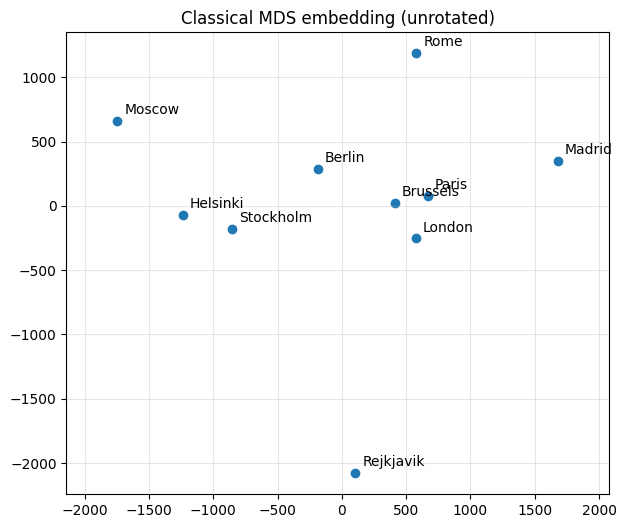

In [3]:
X_cmds = classical_mds(D, 2)
plot_embedding(X_cmds, cities, "Classical MDS embedding (unrotated)",
               filename="a_cmds_embedding.png")

## (b) Rotating the cMDS embedding

A point $x$ (column vector) rotates counterclockwise by $\theta$ via $R(\theta)x$, where $R(\theta) = \begin{pmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix}$. With points stored as rows of $X$, this is $X R(\theta)^T$.

In [4]:
def rotate(X, theta):
    """Rotate each 2-d point (row of X) counterclockwise by theta radians."""
    R = np.array([[np.cos(theta), -np.sin(theta)],
                  [np.sin(theta),  np.cos(theta)]])
    return X @ R.T

Trying several angles:

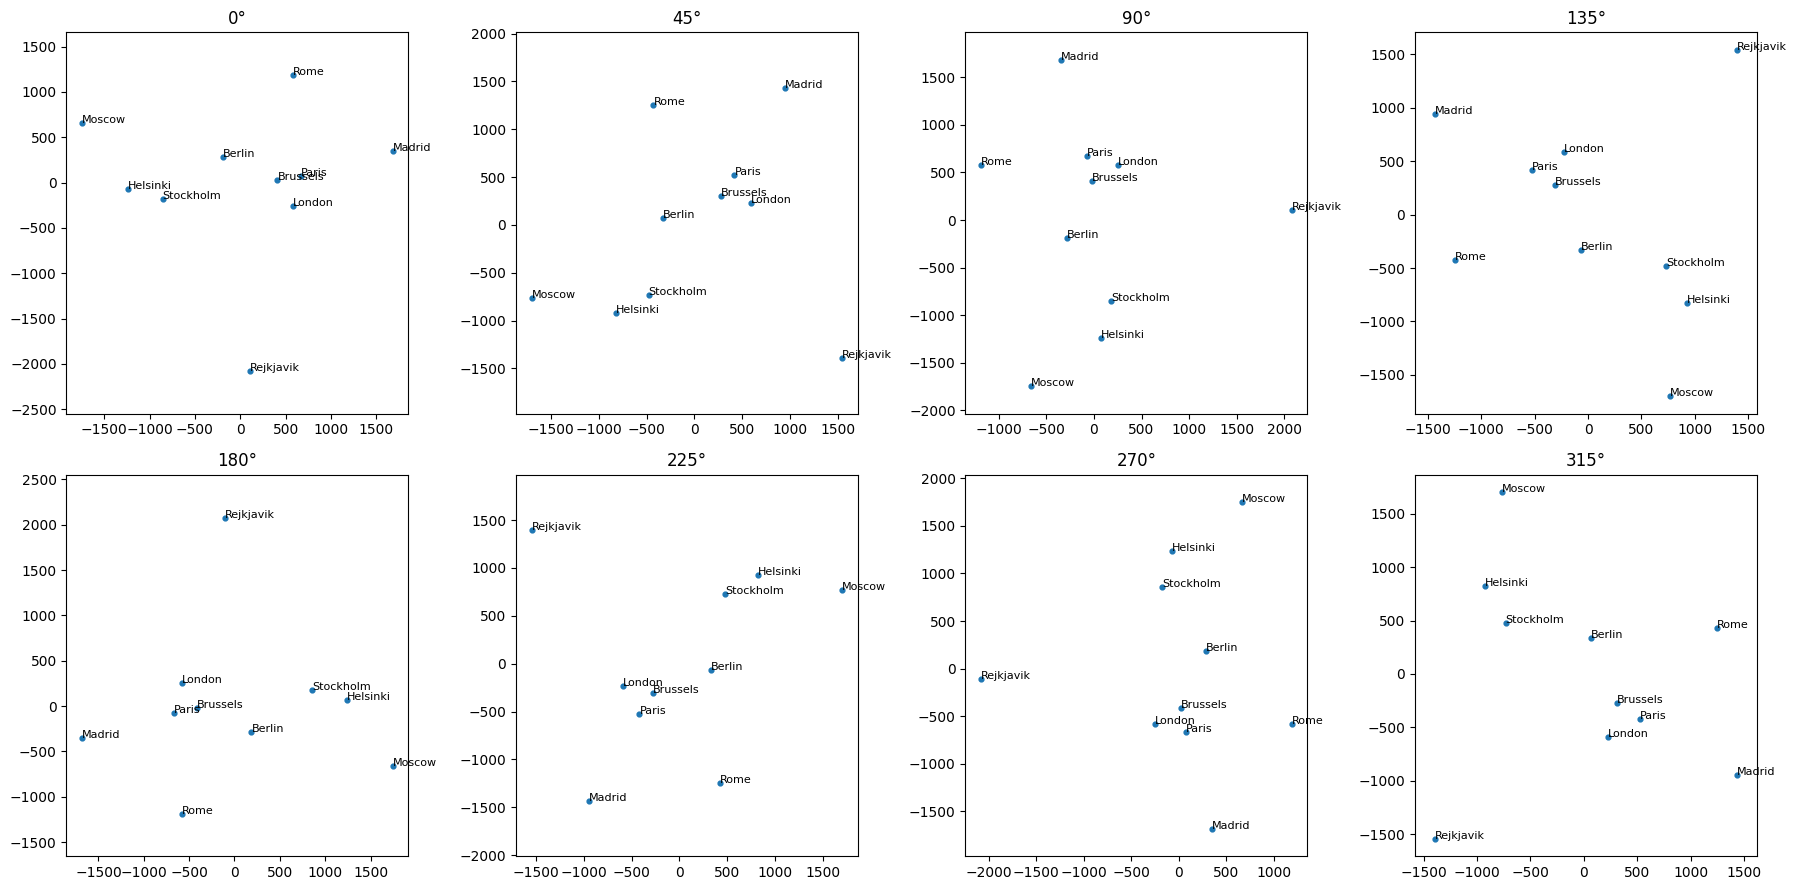

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, deg in zip(axes.ravel(), range(0, 360, 45)):
    Y = rotate(X_cmds, np.radians(deg))
    ax.scatter(Y[:, 0], Y[:, 1], s=12)
    for (x, y), name in zip(Y, cities):
        ax.annotate(name, (x, y), fontsize=8)
    ax.set_title(f"{deg}°")
    ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.savefig("figures/b_cmds_rotation_search.png", dpi=150, bbox_inches="tight")
plt.show()

Around **225°** the map matches real geography: Reykjavik in the northwest, Moscow in the east, Madrid in the southwest, Rome in the south, and Helsinki/Stockholm in the north. No reflection is needed.

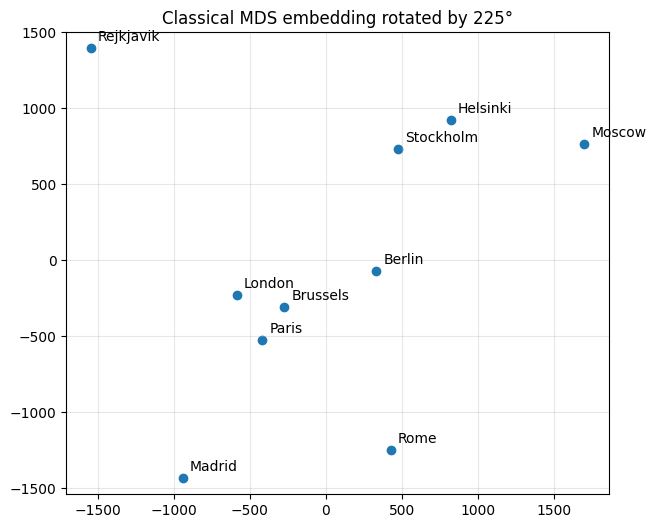

In [6]:
theta_cmds = np.radians(225)
plot_embedding(rotate(X_cmds, theta_cmds), cities, "Classical MDS embedding rotated by 225°",
               filename="b_cmds_rotated_225.png")

## (c) Stress-based MDS with `sklearn.manifold.MDS`

`sklearn.manifold.MDS` minimizes a stress function (SMACOF) instead of using an eigendecomposition. We pass the distance matrix directly with `dissimilarity='precomputed'` and fix `random_state` so the result is reproducible (the rotation angle below depends on it).

stress: 796.0626361534772


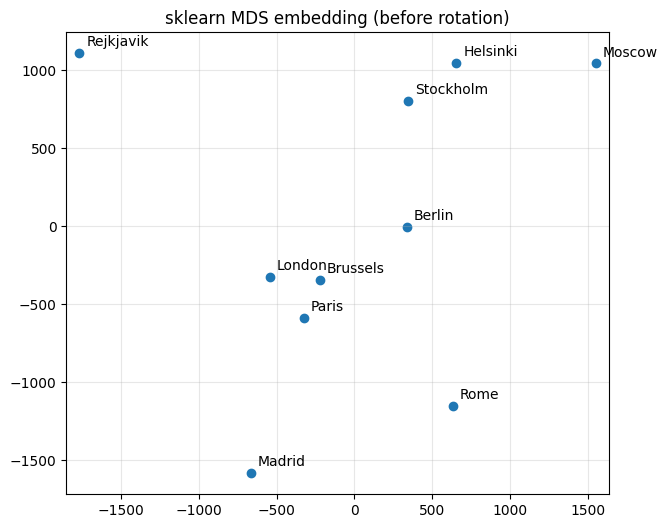

In [7]:
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, n_init=4)
X_sk = mds.fit_transform(D)
print("stress:", mds.stress_)
plot_embedding(X_sk, cities, "sklearn MDS embedding (before rotation)",
               filename="c_sklearn_mds_before_rotation.png")

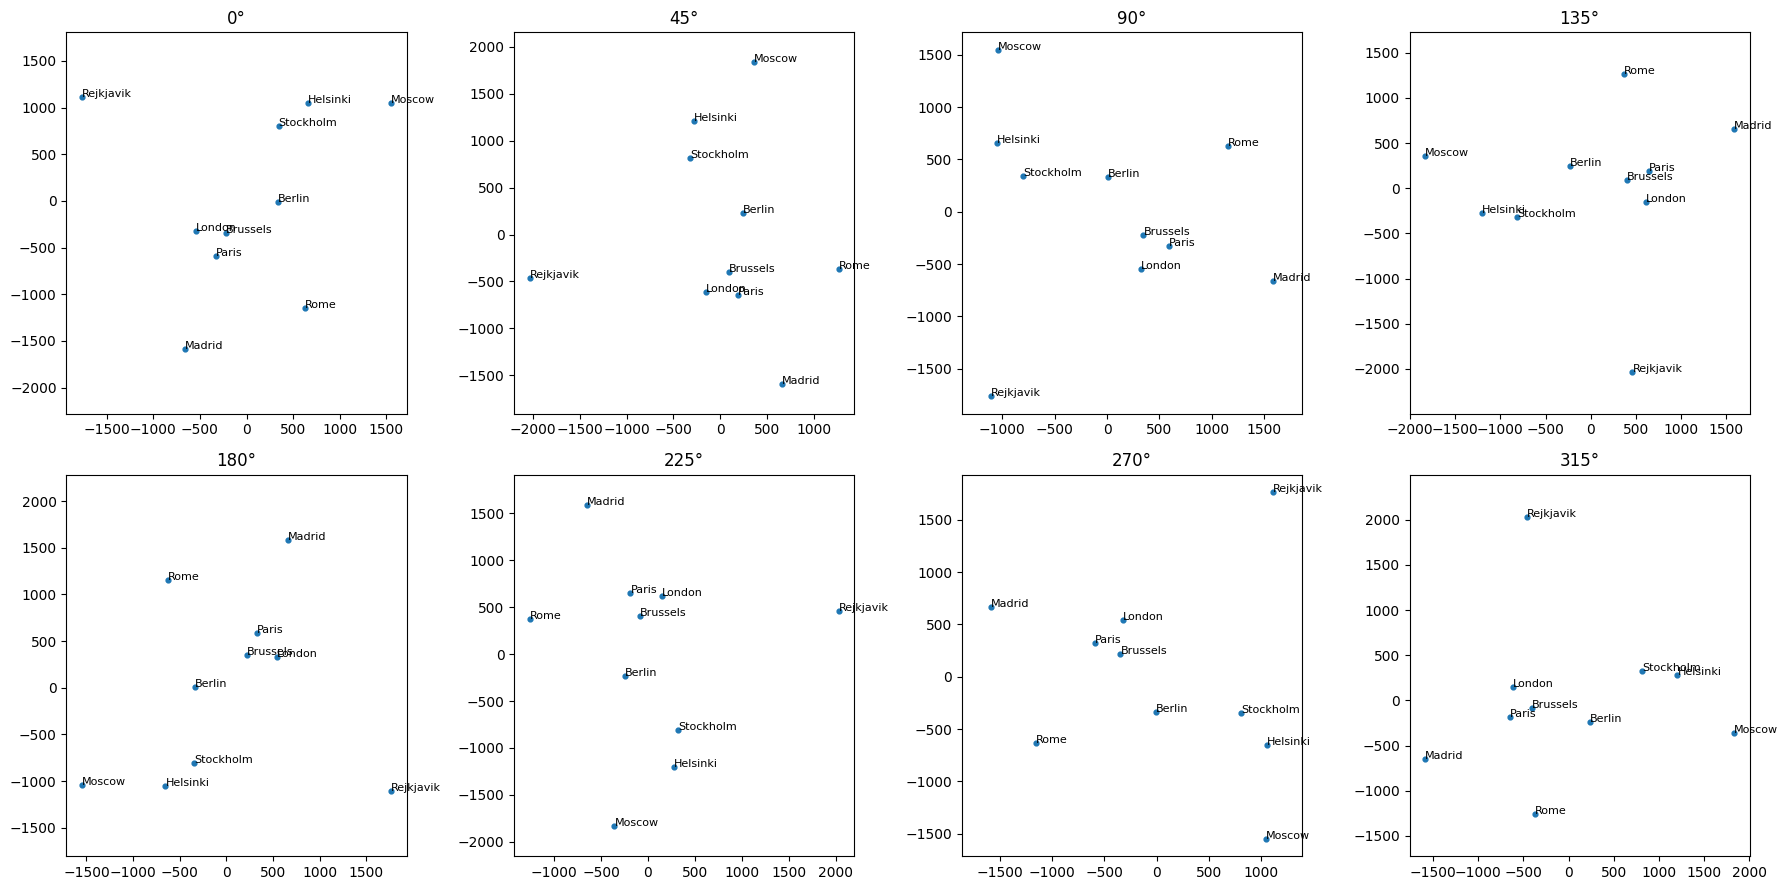

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, deg in zip(axes.ravel(), range(0, 360, 45)):
    Y = rotate(X_sk, np.radians(deg))
    ax.scatter(Y[:, 0], Y[:, 1], s=12)
    for (x, y), name in zip(Y, cities):
        ax.annotate(name, (x, y), fontsize=8)
    ax.set_title(f"{deg}°")
    ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout()
plt.savefig("figures/c_sklearn_rotation_search.png", dpi=150, bbox_inches="tight")
plt.show()

For this embedding (with `random_state=0`), a rotation of about **350°** (i.e. 10° clockwise) gives a layout close to the real map.

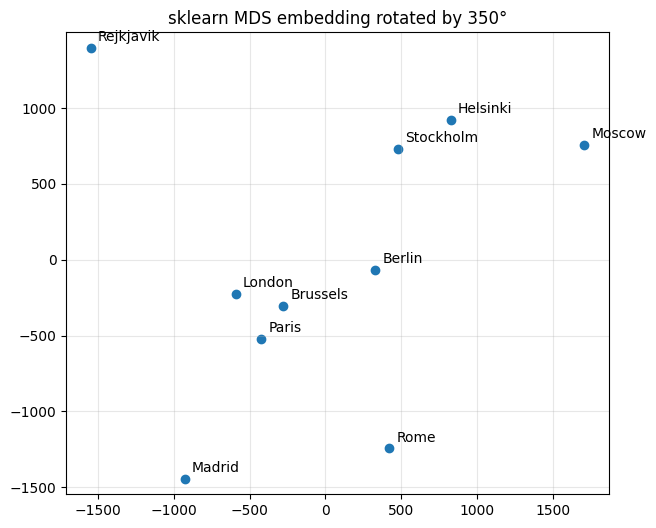

In [9]:
theta_sk = np.radians(350)
plot_embedding(rotate(X_sk, theta_sk), cities, "sklearn MDS embedding rotated by 350°",
               filename="c_sklearn_mds_rotated_350.png")

**Comparison.** Both methods give nearly the same layout up to rotation and translation, so the plots look alike once each is rotated. Small differences remain because cMDS projects onto the top two eigenvectors, while SMACOF directly minimizes the mismatch between embedded and given distances. Neither can fit the data exactly: these are distances on a sphere, which can't be embedded perfectly in a flat plane.